### <font color='gold'> Import les librairies requises

In [1]:
# Importer  packages
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
 # Supprimer les warnings
 import warnings
 warnings.filterwarnings('ignore')

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


###<font color='gold'> Importer et lire les données

In [5]:
# Importer data
df = pd.read_csv('/content/drive/MyDrive/bank/bank_marketing.csv')

#### Description des variables du jeu de données "Bank Marketing"

Ce jeu de données contient des informations sur les clients d'une banque contactés lors de campagnes de marketing direct (appels téléphoniques). L'objectif est d'effectuer une segmentation (clustering) des clients pour identifier des groupes homogènes.

| Variable | Type | Description |
|----------|------|-------------|
| `age` | Numérique | Âge du client (en années). |
| `balance` | Numérique | Solde annuel moyen du compte du client (en euros). |
| `day` | Numérique | Jour du mois du dernier contact. |
| `duration` | Numérique | Durée du dernier contact (en secondes). |
| `campaign` | Numérique | Nombre de contacts effectués avec le client pendant cette campagne. |
| `pdays` | Numérique | Nombre de jours écoulés depuis le dernier contact d'une campagne précédente (-1 = jamais contacté). |
| `previous` | Numérique | Nombre de contacts effectués avant cette campagne. |


In [6]:
# Afficher les données
df.head()

,age,balance,day,duration,campaign,pdays,previous
0,30,1787,19,79,1,-1,0
1,33,4789,11,220,1,339,4
2,35,1350,16,185,1,330,1
3,30,1476,3,199,4,-1,0
4,59,0,5,226,1,-1,0


In [7]:
# Dimension des données
df.shape

(4521, 7)

In [8]:
# Infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   age       4521 non-null   int64
 1   balance   4521 non-null   int64
 2   day       4521 non-null   int64
 3   duration  4521 non-null   int64
 4   campaign  4521 non-null   int64
 5   pdays     4521 non-null   int64
 6   previous  4521 non-null   int64
dtypes: int64(7)
memory usage: 247.4 KB


In [9]:
# décrire les données
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


### <font color='gold'> Preparation des données

In [10]:
# renommer les index
df.index = ['Client ' + str(i) for i in range(1, len(df) + 1)]
df.head()

,age,balance,day,duration,campaign,pdays,previous
Client 1,30,1787,19,79,1,-1,0
Client 2,33,4789,11,220,1,339,4
Client 3,35,1350,16,185,1,330,1
Client 4,30,1476,3,199,4,-1,0
Client 5,59,0,5,226,1,-1,0


In [11]:
# Données en format matriciel
x = df.values

In [12]:
# Importer normalize
from sklearn.preprocessing import normalize
# Normaliser x
x = normalize(x)

In [13]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca_model= PCA(n_components = 2)
# Entrainer le modèle
pca_model.fit(x)
# Matrice des 2 composantes
feature_pca = pca_model.fit_transform(x)
# Convertir la matrice features_pca en dataframe
New_df = pd.DataFrame(feature_pca, columns = ['PCA1', 'PCA2'])

In [14]:
# Part de variance des 2 composantes
np.round(sum(pca_model.explained_variance_ratio_)*100, 2)

np.float64(89.33)

### <font color='gold'> Kmeans

In [15]:
# Importer KMeans
from sklearn.cluster import KMeans

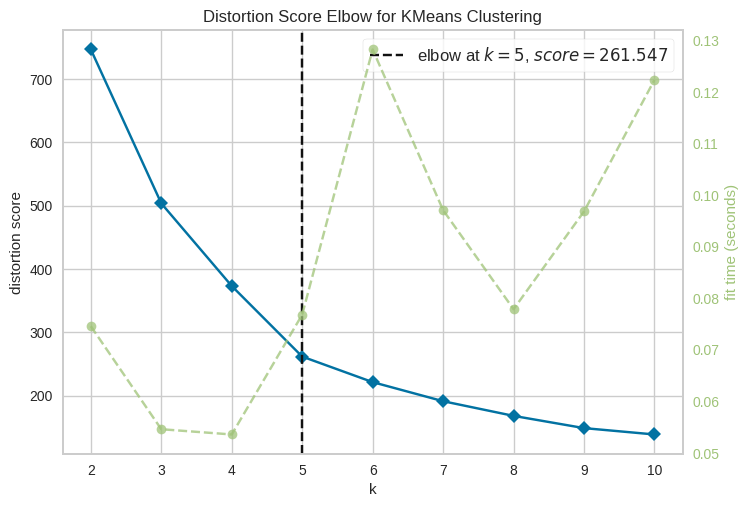

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [16]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

In [17]:
# instantier le modèle
kmeans_model = KMeans(n_clusters = 5, init = 'random', max_iter = 500, random_state = 42)
# Entrainer le modèle
kmeans_model.fit(x)

KMeans(init='random', max_iter=500, n_clusters=5, random_state=42)

#### <font color='teal'> Prédiction

In [19]:
# Prediction de la partition des données
Pred = kmeans_model.predict(x)
# Afficher la partition
Pred

array([0, 0, 0, ..., 3, 0, 0], shape=(4521,), dtype=int32)

In [20]:
# Nombre d'observations dans chaque classe
val = pd.Series(Pred).value_counts()

In [21]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

In [22]:
# Function de visualisuation des classes
def scatter_plot(New_df,Pred):
  fig = px.scatter(New_df, x='PCA1', y='PCA2', color=Pred.astype(str))
  fig.show()

In [23]:
# Visualiser les classes
bar_plot(val)
scatter_plot(New_df, Pred)

##### <font color='teal'> Indice de silhouette de la partition du Kmeans

In [24]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_KM = silhouette_score(x, Pred)
sil_KM

np.float64(0.560683572759043)

### <font color='gold'> CAH

In [25]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

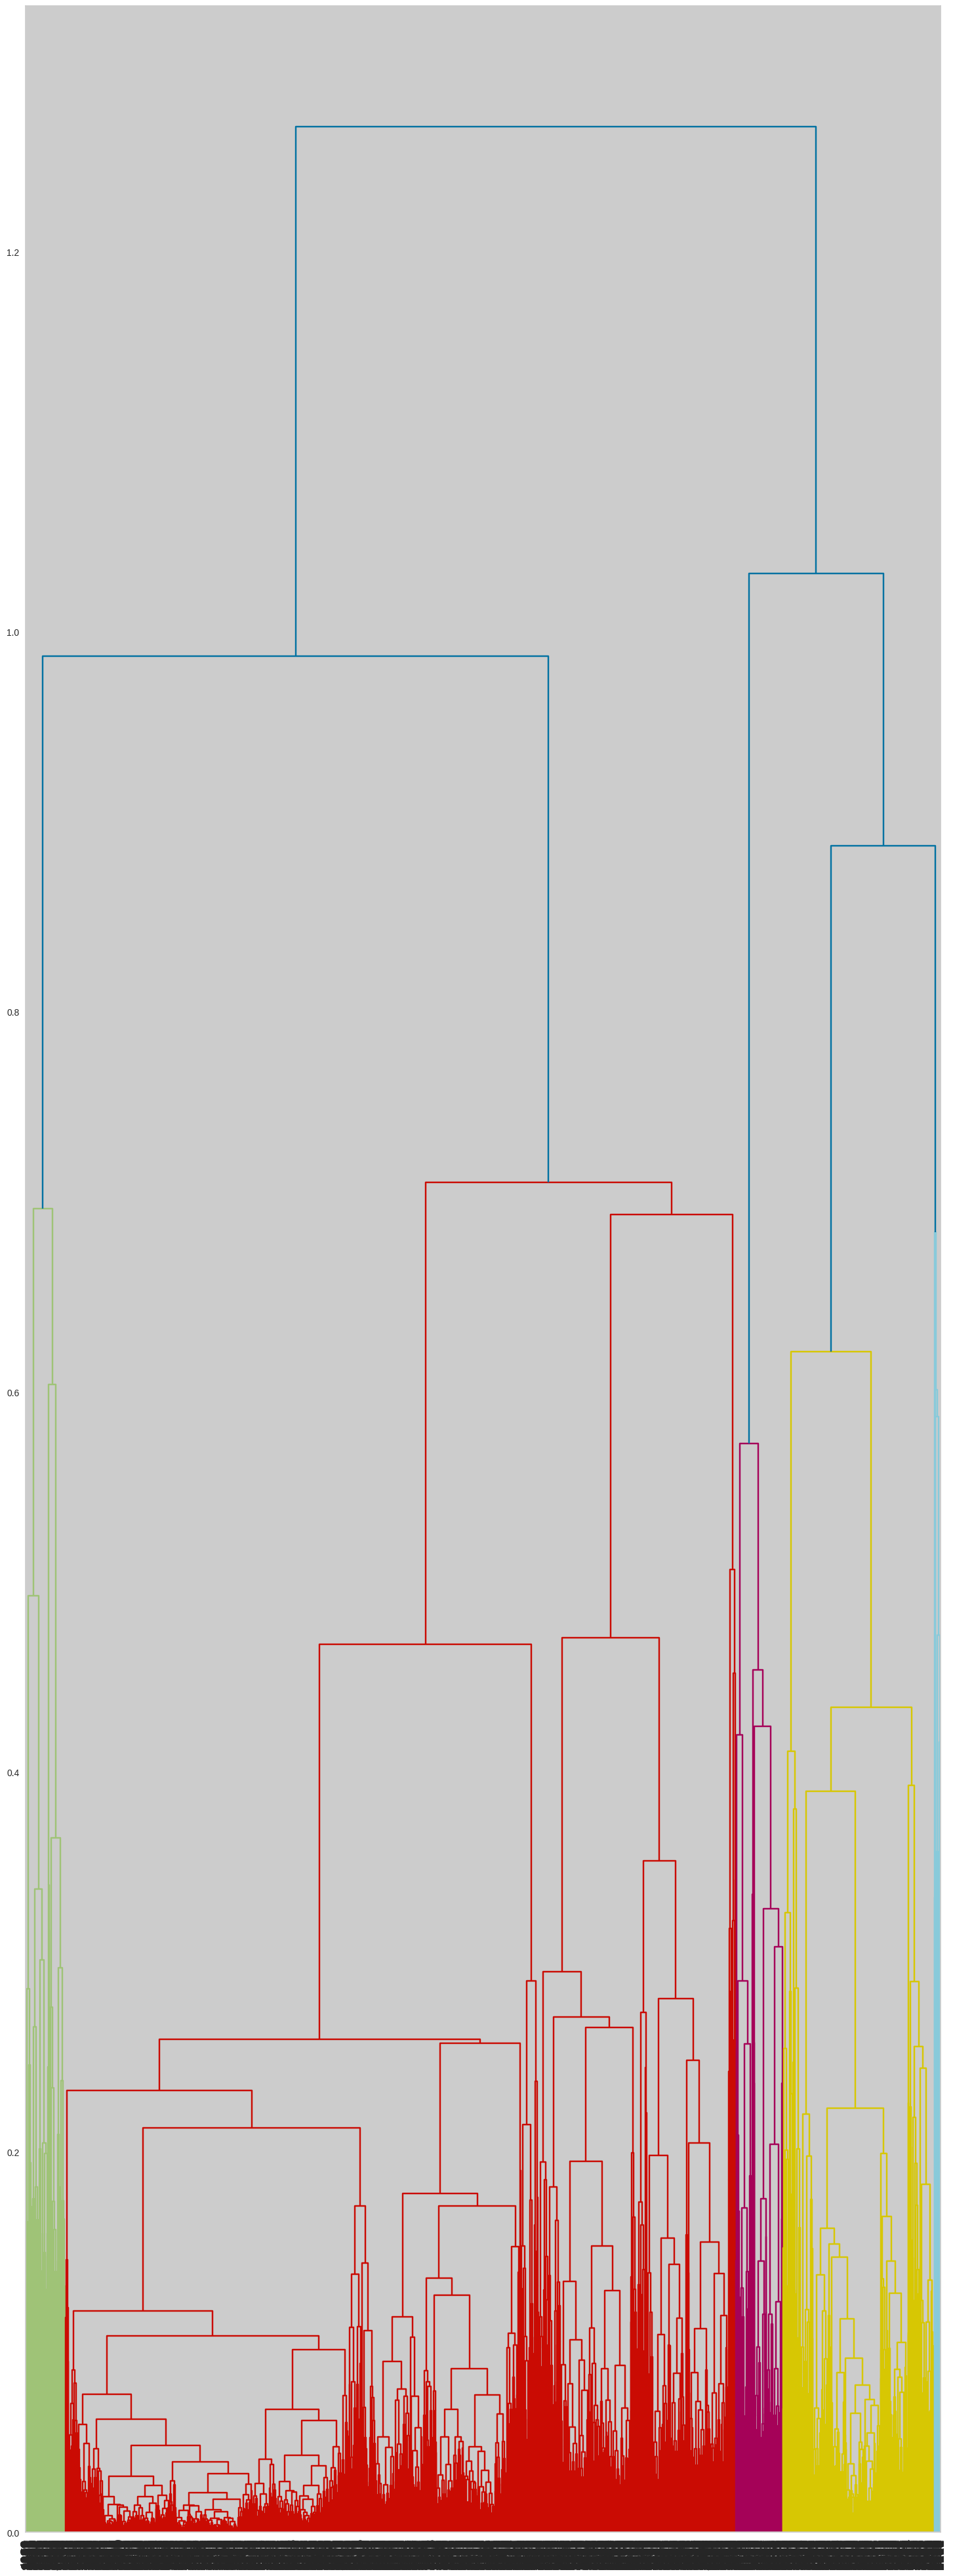

In [26]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(18, 50))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [27]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters = 5, linkage = 'average')
# Entrainer le modèle
cah_model.fit(x)

AgglomerativeClustering(linkage='average', n_clusters=5)

In [28]:
# Prédire la partition des données
pred = cah_model.fit_predict(x)
# Afficher la partition
pred

array([0, 0, 0, ..., 0, 0, 0], shape=(4521,))

In [29]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(pred).value_counts()
val1

,count
0,3312
4,749
2,232
1,198
3,30


In [30]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

In [31]:
# Visualiser les classes
scatter_plot(New_df, pred)

In [32]:
# Silhouette score
sil_CAH = silhouette_score(x, pred)
sil_CAH

np.float64(0.4970049444580747)

In [33]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_KM, sil_CAH]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [34]:
# les indidivus
df.assign(Classe = Pred)

,age,balance,day,duration,campaign,pdays,previous,Classe
Client 1,30,1787,19,79,1,-1,0,0
Client 2,33,4789,11,220,1,339,4,0
Client 3,35,1350,16,185,1,330,1,0
Client 4,30,1476,3,199,4,-1,0,0
Client 5,59,0,5,226,1,-1,0,1
...,...,...,...,...,...,...,...,...
Client 4517,33,-333,30,329,5,-1,0,4
Client 4518,57,-3313,9,153,1,-1,0,4
Client 4519,57,295,19,151,11,-1,0,3
Client 4520,28,1137,6,129,4,211,3,0


In [35]:
# Les individus de la classe 0
df[Pred == 0]

,age,balance,day,duration,campaign,pdays,previous
Client 1,30,1787,19,79,1,-1,0
Client 2,33,4789,11,220,1,339,4
Client 3,35,1350,16,185,1,330,1
Client 4,30,1476,3,199,4,-1,0
Client 6,35,747,23,141,2,176,3
...,...,...,...,...,...,...,...
Client 4510,51,2506,30,210,3,-1,0
Client 4511,36,566,20,129,2,-1,0
Client 4515,38,1205,20,45,4,153,1
Client 4520,28,1137,6,129,4,211,3


## Bilan des deux méthodes

Compare les silhouettes et les profils moyens. Un score plus élevé indique généralement des groupes mieux séparés, mais il faut aussi vérifier la répartition et le sens des variables. Les numéros de groupe sont arbitraires.

La création de l’interface Streamlit se fera dans un fichier séparé afin de garder ce notebook centré sur l’analyse.

In [ ]:
comparaison = pd.DataFrame({"Méthode": ["K-means", "CAH"], "Silhouette": [sil_KM, sil_CAH]})
comparaison

In [ ]:
print("Profil moyen — K-means")
display(df.assign(Groupe=Pred).groupby("Groupe").mean(numeric_only=True).round(2))
print("Profil moyen — CAH")
display(df.assign(Groupe=pred).groupby("Groupe").mean(numeric_only=True).round(2))